## `model_analysis.ipynb`

This file is used to perform the analyses including in Figures 4 and 5 of the paper.

## Settings

In [1]:
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as mticker # used for percentage ticks
import colorsys # define colors in HLS

# Stats packages
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy.stats import linregress
from scipy.stats import ks_2samp, levene

# Misc
import warnings
import sys
import os
from IPython.display import display

import testis_model as tm

In [2]:
from analysis import *

There are 3 real clones that have < 2 observation times.


In [3]:
small_label_settings = {
    'font.family': 'Arial',
    'font.size': 7,              # base font size
    'xtick.labelsize': 5,        # x-axis tick label size
    'ytick.labelsize': 5,        # y-axis tick label size
    'axes.labelsize': 7,         # axis label size
    'axes.titlesize': 7,         # title size
    'legend.fontsize': 7,        # legend font size
    'figure.titlesize': 7        # figure title size
}

In [4]:
# def hue(r):
#     """
#     This function inputs a drift rate `r` and outputs a shade of blue.
#     Lower values of `r` correspond to darker shades.

#     This function is used to make colors consistent across the figures.
#     """
#     lamb = (symlog10(r) - symlog10(0)) / (symlog10(36) - symlog10(0))
#     return colorsys.hls_to_rgb(0.5, 0.30 + 0.45 * lamb, 0.5)

# exp_hue = '#ffc566'
# trunc_hue = '#c56eeb'
# no_collapse_hue = '#3ddb6f'

In [5]:
# hue(2)

In [6]:
# def symlog10(x, linthresh=1e-2):
#     return np.sign(x) * np.log10(1 + np.abs(x) / linthresh)

# def inv_symlog10(y, linthresh=1e-2):
#     return np.sign(y) * ((10**np.abs(y) - 1) * linthresh)

## Load in data

In [7]:
# file_path = os.path.join('..', 'model_simulations', 'all_clone_results.csv')
# df = pd.read_csv(file_path)

# exp_scenario = 'full_pipeline'

# invalid_real_entries = df.query('scenario == @exp_scenario').query('n_transient < 2')
# if len(invalid_real_entries) > 0:
#     print(f'There are {len(invalid_real_entries)} real clones that have < 2 observation times.')

# # Only include data that has at least 2 observations and are not trivial.
# df = df.query('n_transient > 1').copy()

# print(f'The loaded clone data has {len(df)} rows.')

In [8]:
# # Compute additional columns 

# df['l_gap'] = df['l_max'] - df['l_null']

# # Test statistic 3.84 corresponds to
# # an alpha=0.05 signifiance level.
# df['pass_null'] = 2 * df['l_gap'] > 3.84

# with np.errstate(divide='ignore', invalid='ignore'):
#     df['log_r'] = np.log(df['r_opt'])
#     df['log10_r'] = np.log10(df['r_opt'])
    
# df['symlog10_r'] = symlog10(df['r_opt'])

# df.head()

In [9]:
mean_r = df[df['scenario'] == 'full_pipeline']['r_opt'].mean()
med_r = df[df['scenario'] == 'full_pipeline']['r_opt'].median()
mean_symlog_r = inv_symlog10(df[df['scenario'] == 'full_pipeline']['symlog10_r'].mean())

print(f'The mean estimate of rp in the experimental data is {mean_r:.2f}. \
The median is {med_r:.2f}. The mean taken in symlog space is {mean_symlog_r:.2f}.')

The mean estimate of rp in the experimental data is 10.66. The median is 2.02. The mean taken in symlog space is 2.18.


In [10]:
failed_converge = df[df['l_max'] < -1e5]
if len(failed_converge) > 0:
    print('The following rows did not have a convergent likelihood calculation:')
    display(failed_converge)
else:
    print('All likelihood calculations converged successfully.')

All likelihood calculations converged successfully.


## Quantify model prediction bias (Supplementary Table)

In [11]:
rp_values = [0, 0.5, 2, 5, 8, 15, 25]
rows = []

for rp in rp_values:
    scenario = f'r36_rp{rp}_mimic'
    df2 = df.query('scenario == @scenario')
    mean = np.mean(df2['r_opt'])
    std  = np.std(df2['r_opt'])
    contains_true = ((df2['lower'] <= rp) & (df2['upper'] >= rp)).mean()

    relative_bias = np.nan if rp == 0 else (mean - rp) / rp
    
    rows.append({
        'rp': rp,
        'mean ± SD': f'{mean:.2f} ± {std:.2f}',
        'relative bias': f'{100*relative_bias:.2f}%',
        '% correct interval': f'{100*contains_true:.2f}%',
    })

results_df = pd.DataFrame(rows)
results_df

,rp,mean ± SD,relative bias,% correct interval
0,0.0,0.05 ± 0.19,nan%,97.93%
1,0.5,0.54 ± 0.55,8.19%,96.04%
2,2.0,1.94 ± 1.50,-3.17%,95.12%
3,5.0,4.68 ± 3.49,-6.33%,94.60%
4,8.0,7.43 ± 4.98,-7.10%,94.46%
5,15.0,13.96 ± 9.03,-6.93%,95.26%
6,25.0,23.82 ± 16.68,-4.71%,93.92%


In [12]:
len(df.query('scenario == "r36_rp2_mimic"'))

1721

## Panel 4c

Load in fish and clone data.

In [11]:
model_simulations_path = os.path.join('..', 'model_simulations')

# Add to sys.path if not already present
if model_simulations_path not in sys.path:
    sys.path.append(model_simulations_path)
    print("Added to path:", model_simulations_path)
    
from saving_loading import find_scenarios, load_all_scenarios

scenarios_directory = os.path.join('..', 'model_simulations', 'scenarios')
fish_data, clone_data = load_all_scenarios('full_pipeline', directory = scenarios_directory)

fish_id = 1
fish = fish_data[exp_scenario, fish_id, 0]

Added to path: ../model_simulations


Plot experimental fish to be used in figure.

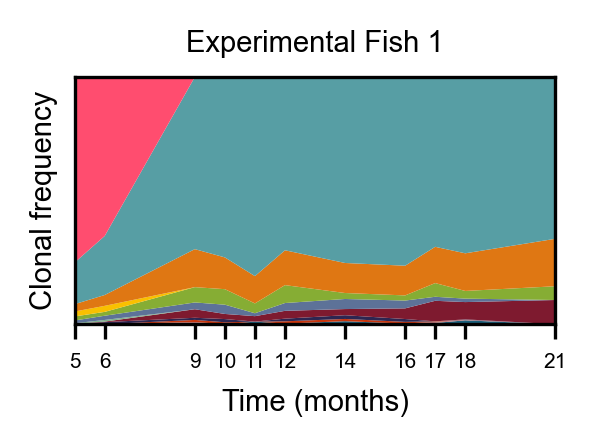

In [12]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(figsize = (2, 1.5), dpi=300)
tm.visualize.plot(fish, ax = ax)
ax.set_yticks([])
ax.set_xlabel('Time (months)')
ax.set_title('Experimental Fish 1')

plt.tight_layout()

filepath = os.path.join('images', 'fish1.svg')
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

## Panel 4d

In [13]:
scenarios = ['r36_rp0_mimic', 'r36_rp2_mimic', exp_scenario]
scenarios_labels = ['Model\n$rp=0$', 'Model\n$rp=2$', 'Exp. data']
mapping = dict(zip(scenarios, scenarios_labels))

df2 = df.query('scenario.isin(@scenarios)').copy()
df2['scenario'] = df2['scenario'].map(mapping)

overall_pass = df2.groupby('scenario', as_index = False).agg({'pass_null': 'mean'})
overall_pass['percent_pass'] = overall_pass['pass_null'] * 100
overall_pass['order'] = [2, 0, 1]
overall_pass

,scenario,pass_null,percent_pass,order
0,Exp. data,0.873646,87.364621,2
1,Model\n$rp=0$,0.022115,2.211538,0
2,Model\n$rp=2$,0.872748,87.274840,1


In [14]:
for x, label in enumerate(scenarios_labels):
    print(overall_pass.loc[x, 'percent_pass'])

87.36462093862815
2.2115384615384617
87.27484020918071


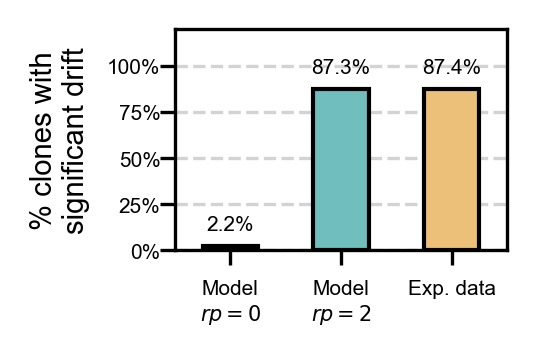

In [15]:
# sns.set_theme(style = 'whitegrid')
plt.style.use('default')
plt.rcParams.update(small_label_settings)
plt.figure(figsize = (1.8, 1.2), dpi = 300)

palette = {
    'Model\n$rp=0$': hue(0),
    'Model\n$rp=2$': hue(2),
    'Exp. data': exp_hue
}

order = ['Model\n$rp=0$', 'Model\n$rp=2$', 'Exp. data']

ax = sns.barplot(
    data=overall_pass, x='scenario', y='percent_pass',
    edgecolor='black', hue='scenario', palette=palette, legend=False,
    width = 0.5, order = ['Model\n$rp=0$', 'Model\n$rp=2$', 'Exp. data'], zorder = 2
)

# Grid styling
ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis = 'y', zorder=-1)

plt.ylabel("% clones with\nsignificant drift")
plt.xlabel('')
plt.xticks(rotation=0, ha='center')

for i, row in overall_pass.iterrows():
    x = row['order']
    percent_pass = row['percent_pass']
    ax.annotate(
        f'{percent_pass:.1f}%',
        (x, percent_pass),
        ha = 'center', va = 'bottom',
        fontsize = 5, color = 'black', xytext = (0, 3),
        textcoords = 'offset points'
    )

ax.set_ylim(0, 120)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.tick_params(axis='y', pad = 0)
ax.set_yticks([0, 25, 50, 75, 100])

plt.tight_layout()

filepath = os.path.join('images', 'null_hypothesis.svg')
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

## Panel 4e

In [50]:
sim_scenario = 'r36_rp2_mimic'

def logistic_model(df, dep_var, scenario, duplicate):
    df2 = df.query('scenario == @scenario and duplicate == @duplicate').copy()

    # Fit logistic regression
    X = sm.add_constant(df2[dep_var])
    y = df2['pass_null']
    model = sm.Logit(y, X).fit(disp=False)
    return model, df2

dep_var = 'last_time'
model, df2 = logistic_model(df, dep_var, sim_scenario, 0)

last_time = model.params[dep_var]
p = model.pvalues[dep_var]
print(f'The coefficient of {dep_var} is {last_time:.3f} with p={p:.2e}.')

model.summary()

The coefficient of last_time is 0.131 with p=1.02e-02.


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:              pass_null   No. Observations:                  174
Model:                          Logit   Df Residuals:                      172
Method:                           MLE   Df Model:                            1
Date:                Mon, 29 Dec 2025   Pseudo R-squ.:                 0.07668
Time:                        09:11:44   Log-Likelihood:                -53.434
converged:                       True   LL-Null:                       -57.871
Covariance Type:            nonrobust   LLR p-value:                  0.002891
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3374      0.669      0.504      0.614      -0.975       1.650
last_time      0.1309      0.051      2.569      0.010       0.031       0.231
==============================================================================
"""

In [17]:
# Generate a grid of last_time values across the observed range
x_vals = np.linspace(4, 28, 200)
X_pred = sm.add_constant(x_vals)

# Predicted probabilities from the logistic model
y_pred = model.predict(X_pred)

# --- Compute confidence intervals ---
# Get covariance matrix of parameters
cov = model.cov_params()
params = model.params.values

# Linear predictor and its variance
lin_pred = X_pred @ params
var_lin_pred = np.sum((X_pred @ cov) * X_pred, axis=1)
se_lin_pred = np.sqrt(var_lin_pred)

# 95% CI on logit scale, then transform back to probability
logit_lower = lin_pred - 1.96 * se_lin_pred
logit_upper = lin_pred + 1.96 * se_lin_pred
ci_lower = 1 / (1 + np.exp(-logit_lower))
ci_upper = 1 / (1 + np.exp(-logit_upper))

3 20


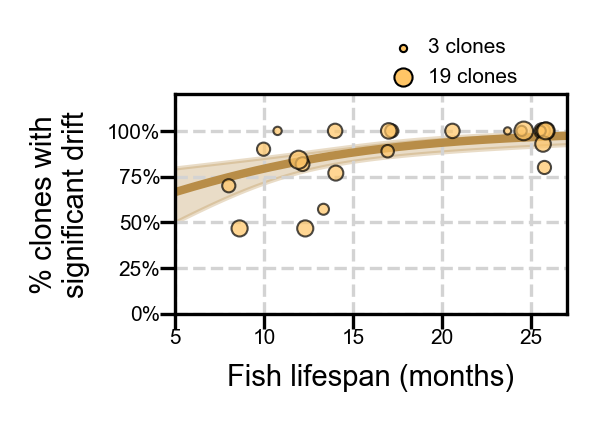

In [18]:
plt.rcParams.update(small_label_settings)
fig, ax = plt.subplots(figsize = (2, 1.4), dpi = 300)

agg = df2.groupby(['fish']).agg({'pass_null': 'mean', 'max_time': 'first', 'clone': 'count'})
agg['pass_null'] = agg['pass_null'] * 100
print(agg['clone'].min(), agg['clone'].max())

rng = np.random.default_rng()
x_jittered = agg['max_time'] + rng.uniform(-0.25, 0.25, size=len(agg))
ax.scatter(x_jittered, agg['pass_null'], color = '#ffc566',
    edgecolors='black',       # stroke color
    linewidths=0.5,           # stroke thickness
     zorder=5,
    s = agg['clone'],
          alpha = 0.7)
# Logistic fit
ax.plot(x_vals, 100*y_pred, color="#b88d48", linewidth=2, label="Logit fit")

# Confidence interval band
ax.fill_between(x_vals, 100*ci_lower, 100*ci_upper, color="#b88d48", alpha=0.3, label="95% CI")
ax.set_xlabel('Fish lifespan (months)')
ax.set_ylabel('% clones with\nsignificant drift')

ax.set_ylim(0, 120)
ax.set_xlim(5, 27)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_xticks([5, 10, 15, 20, 25])

# Custom legend handles as before
sizes = [3, 19]
legend_handles = [
    plt.scatter([], [], s=size, color='#ffc566',
                edgecolors='black', linewidths=0.5)
    for size in sizes
]

leg = ax.legend(
    legend_handles,
    [f"{size} clones" for size in sizes],
    frameon=False,
    loc="lower center",
    bbox_to_anchor=(0.7, 0.95),  # adjust horizontal position
    ncol=1,
    fontsize=5,
    handletextpad=0.2
)

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')

# ax.text(13, 28, 'Fish 16', fontsize=5, ha='center')
# ax.text(7.5, 20, 'Fish 13', fontsize=5, ha='center')
# ax.text(24, 56, 'Fish 10', fontsize=5, ha='center')
# ax.text(9, 105, 'Fish 40, 45', fontsize=5, ha='center')

ax.yaxis.set_tick_params(pad=0)   # smaller pad brings labels closer
ax.xaxis.set_tick_params(pad=0)   # smaller pad brings labels closer

plt.tight_layout()
plt.savefig('images/lifespan_null.svg', bbox_inches = 'tight', pad_inches = 0)

In [20]:
sim_scenario = 'r36_rp2_mimic'

rows = []
for d in df['duplicate'].unique():
    model, df2 = logistic_model(df, sim_scenario, d)
    
    last_time = model.params['last_time']
    p = model.pvalues['last_time']

    row = {'Duplicate': d, 'coef': last_time, 'p': p}
    rows.append(row)
    # print(f'For duplicate {d}, the coefficient of last_time is {last_time:.3f} with p={p:.3g}.')

results_df = pd.DataFrame(rows)
results_df

,Duplicate,coef,p
0,0,0.130850,0.010198
1,1,0.168484,0.005065
2,2,0.194399,0.000733
3,3,0.333747,0.000516
4,4,0.306300,0.000111
5,5,0.202405,0.000706
6,6,0.230305,0.001321
7,7,0.189498,0.000169
8,8,0.152716,0.001282
9,9,0.196107,0.000753


## Panel 5a

In [140]:
# supplement_mode: determines whether to plot the figure that goes in
# the main body, or the extended version in the supplement.
supplement_mode = True

# Define mapping from scenario string to numeric r
scenario_map = {
    'full_pipeline': 'Exp. data',
    'r36_rp0.5_mimic': 'Model\n$rp=0.5$',
    'r36_rp2_mimic': 'Model\n$rp=2$',
    'r36_rp8_mimic': 'Model\n$rp=8$',
    'r36_rp25_mimic': 'Model\n$rp=25$'
}

palette = {
    'Exp. data': exp_hue,
    'Model\n$rp=0.5$': hue(0.5),
    'Model\n$rp=2$': hue(2),
    'Model\n$rp=8$': hue(8),
    'Model\n$rp=25$': hue(25),
}

if supplement_mode:
    scenario_map.update({
        'full_pipeline_trunc': 'Exp. data\n(truncated)',
        'no_collapse': 'Exp. data\n(no collapse)'
    })

    palette.update({
        'Exp. data\n(truncated)': trunc_hue,
        'Exp. data\n(no collapse)': no_collapse_hue
    })

    order = ['Exp. data', 'Exp. data\n(truncated)', 'Exp. data\n(no collapse)', 
         'Model\n$rp=0.5$', 'Model\n$rp=2$', 'Model\n$rp=8$', 'Model\n$rp=25$']
else:
    order = ['Exp. data', 'Model\n$rp=0.5$', 'Model\n$rp=2$', 'Model\n$rp=8$', 'Model\n$rp=25$']

df_plot = df.query('scenario.isin(@scenario_map.keys())').copy()
df_plot = df_plot.query('duplicate == 0').copy()
df_plot['scenario_label'] = df_plot['scenario'].map(scenario_map)

zero_counts = df_plot.groupby('scenario_label')['r_opt'].apply(lambda x: (x==0).mean()*100)

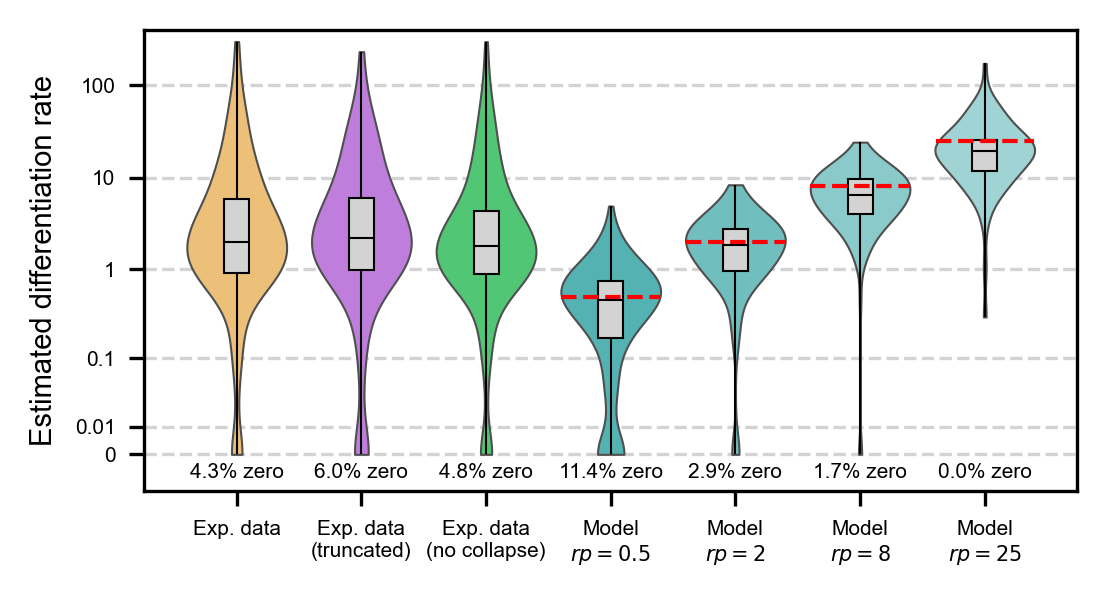

In [142]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, ax = plt.subplots(figsize = (3.7, 2), dpi = 300)    

sns.violinplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    inner=None, cut=0, hue='scenario_label',
    density_norm='area', linewidth=0.5, palette=palette, ax=ax, legend=False
)

sns.boxplot(
    data=df_plot, x='scenario_label', y='symlog10_r',
    order=order,
    whis=np.inf, width=0.2, showcaps=False,
    boxprops={'facecolor':'lightgray', 'edgecolor':'black', 'linewidth':0.5},
    whiskerprops={'color':'black', 'linewidth':0.5},
    capprops={'color':'black', 'linewidth':0.5},
    medianprops={'color':'black', 'linewidth':0.5},
    ax=ax
)

# "True" r values in red dashed lines
for i, r in enumerate([0.5, 2, 8, 25]):
    col = i + (len(order) - 4)
    y_val = symlog10(r, linthresh=1e-2)  
    
    poly = ax.collections[col]
    verts = poly.get_paths()[0].vertices
    mask = np.isclose(verts[:,1], y_val, atol=0.05)  # tolerance around y_val
    x_coords = verts[mask,0]
    
    xmin, xmax = x_coords.min(), x_coords.max()
    ax.hlines(
        y_val, xmin, xmax, colors='red', linestyles='dashed', linewidth=1
    )

for i, key in enumerate(order):
    pct = zero_counts.get(key, 0)
    ax.text(
        i, -0.2, f"{pct:.1f}% zero",
        ha='center', va='center', fontsize=5
    )

ax.set_xlabel('')

# Set y ticks.
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
ax.set_yticks(tick_symlog)
ax.set_yticklabels([str(r) for r in tick_r])
ax.set_ylim([-0.4, 4.6])
ax.set_ylabel('Estimated differentiation rate')

ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')
ax.set_axisbelow(True) 

plt.tight_layout()

if supplement_mode:
    filepath = os.path.join('images', 'violin_supplement.svg')
else:
    filepath = os.path.join('images', 'violin.svg')
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

## Panel 5b

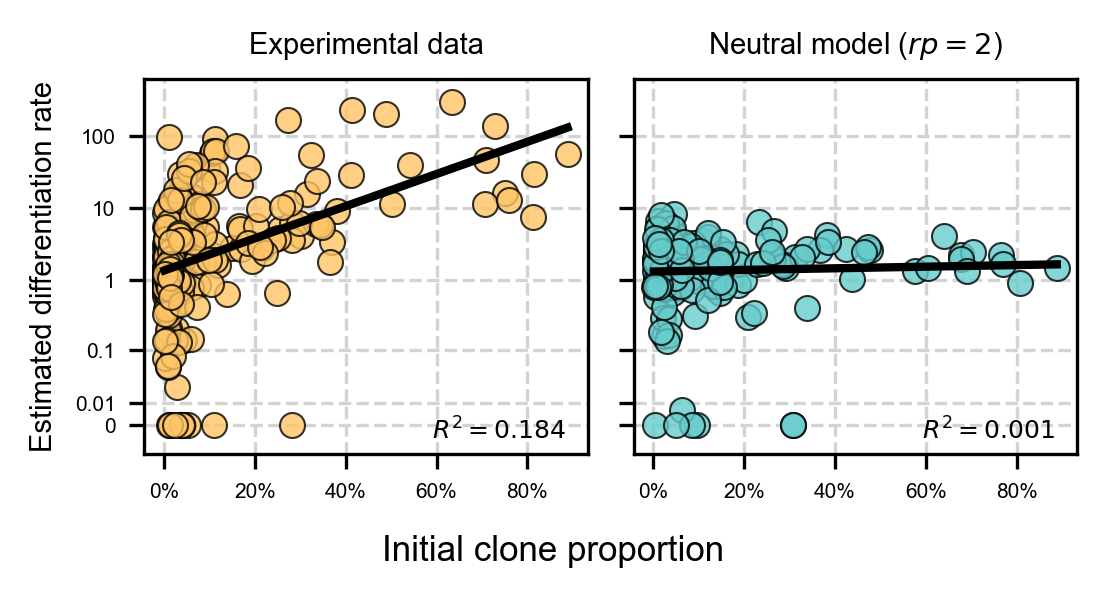

In [23]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

dep_var = 'symlog10_r'

exp_df = df.query('scenario == @exp_scenario and ~r_opt.isna()').copy()
sim_df  = df.query('scenario == @sim_scenario and ~r_opt.isna() and duplicate == 0').copy()

# Fit regressions
slope_exp, intercept_exp, r_exp, p_exp, stderr_exp = linregress(exp_df['init_freq'], exp_df['symlog10_r'])
slope_sim, intercept_sim, r_sim, p_sim, stderr_sim = linregress(sim_df['init_freq'], sim_df['symlog10_r'])

# X values for smooth line
x_exp = np.linspace(exp_df['init_freq'].min(), exp_df['init_freq'].max(), 200)
x_sim = np.linspace(sim_df['init_freq'].min(), sim_df['init_freq'].max(), 200)

# Predicted values
y_exp = intercept_exp + slope_exp * x_exp
y_sim = intercept_sim + slope_sim * x_sim

# Plot
fig, axes = plt.subplots(1, 2, figsize=(3.7, 2), dpi = 300, sharey=True)

palette = {
    'Model\n$rp=0$': hue(0),
    'Model\n$rp=1$': hue(1),
    'Exp. data': exp_hue
}

# Grid styling
for ax in axes:
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray')
    ax.set_axisbelow(True) 

line_color = 'black'

# Experimental scenario
axes[0].scatter(exp_df['init_freq'], exp_df['symlog10_r'], color = exp_hue, alpha=0.8, edgecolor="black", linewidth=0.5)
axes[0].plot(x_exp, y_exp, color=line_color, linewidth=2)
axes[0].set_title('Experimental data')

# Simulation scenario
axes[1].scatter(sim_df['init_freq'], sim_df['symlog10_r'], color = hue(2.5), alpha=0.8, edgecolor="black", linewidth=0.5)
axes[1].plot(x_sim, y_sim, color=line_color, linewidth=2)
axes[1].set_title("Neutral model ($rp=2$)")


axes[0].set_ylabel("Estimated differentiation rate")
# Y-axis ticks
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
axes[0].set_ylim([-0.4, 4.8])
axes[0].set_yticks(tick_symlog)
axes[0].set_yticklabels([str(r) for r in tick_r])

axes[0].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))

fig.supxlabel("Initial clone proportion", y=0.05)

# Annotate R^2 values at bottom right of each axis
axes[1].text(0.95, 0.025, f"$R^2 = {r_sim**2:.3f}$",
             transform=axes[1].transAxes, ha='right', va='bottom', fontsize=6)
axes[0].text(0.95, 0.025, f"$R^2 = {r_exp**2:.3f}$",
             transform=axes[0].transAxes, ha='right', va='bottom', fontsize=6)

plt.tight_layout()
plt.savefig('./images/correlation.svg', bbox_inches = 'tight', pad_inches = 0)

In [94]:
def linear_mm(df, exp_scenario, sim_scenario, sim_duplicate):
    df2 = df[
        (df['scenario'] == exp_scenario) |
        ((df['scenario'] == sim_scenario) & (df['duplicate'] == sim_duplicate))
    ].copy()

    # Set scenario as categorial and re-order.
    df2['scenario'] = pd.Categorical(df2['scenario'])
    df2['scenario'] = df2['scenario'].cat.reorder_categories(
        [sim_scenario, exp_scenario]
    )
    
    # Center data
    df2['init_freq_c'] = df2['init_freq']  - df2['init_freq'].mean()
    df2['log_r_c']     = df2['symlog10_r'] - df2['symlog10_r'].mean()

    model = smf.mixedlm(
        "log_r_c ~ init_freq_c * scenario",
        data=df2,
        groups=df2["fish"],
        re_formula="~ 1"
    ).fit(method="lbfgs")
    return model, df2

In [98]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

model, df2 = linear_mm(df, exp_scenario, sim_scenario, 0)
model.summary()

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)


<class 'statsmodels.iolib.summary2.Summary'>
"""
                     Mixed Linear Model Regression Results
================================================================================
Model:                     MixedLM         Dependent Variable:         log_r_c  
No. Observations:          451             Method:                     REML     
No. Groups:                24              Scale:                      0.4145   
Min. group size:           5               Log-Likelihood:             -456.6539
Max. group size:           30              Converged:                  Yes      
Mean group size:           18.8                                                 
--------------------------------------------------------------------------------
                                      Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------------
Intercept                             -0.105    0.066 -1.578 0.115 -0.235  0.025
scenario[T.full_pipeline]              0.227    0.063  3.591 0.000  0.103  0.352
init_freq_c                            0.037    0.267  0.137 0.891 -0.487  0.560
init_freq_c:scenario[T.full_pipeline]  2.156    0.360  5.996 0.000  1.452  2.861
Group Var                              0.043    0.032                           
================================================================================

"""

In [96]:
print(f"The significance of initial frequency on simulated data is {model.pvalues['init_freq_c']:.3g}.")
print(f"The significance of interaction on initial frequency is {model.pvalues['init_freq_c:scenario[T.full_pipeline]']:.3g}.")

The significance of initial frequency on simulated data is 0.877.
The significance of interaction on initial frequency is 3.67e-09.


In [97]:
exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

rows = []
for d in df['duplicate'].unique():
    model, df2 = linear_mm(df, exp_scenario, sim_scenario, d)
    interact_p = model.pvalues[f'init_freq_c:scenario[T.{exp_scenario}]']
    sim_p = model.pvalues['init_freq_c']
    
    # print(f'For duplicate {d}, the simulation p is {sim_p:.3g} and the interaction p is {interact_p:.3g}.')
    row = {'Duplicate': d, 'simulation p': sim_p, 'interaction p': interact_p}
    rows.append(row)

results_df = pd.DataFrame(rows)
results_df

/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/opt/anaconda3/envs/tm_test/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.p

,Duplicate,simulation p,interaction p
0,0,0.890956,2.018946e-09
1,1,0.732254,1.274339e-10
2,2,0.527924,2.631185e-11
3,3,0.250768,1.138285e-12
4,4,0.786000,2.984504e-09
5,5,0.003621,9.303113e-17
6,6,0.284720,4.724715e-12
7,7,0.876685,3.671326e-09
8,8,0.433320,8.594143e-12
9,9,0.660251,7.875268e-11


## Panel 5c

In [28]:
def make_summary(df):
    """
    For each fish, compute the mean clone drift rate +/-
    1.96 * the standard error.
    """
    summary = (
        df.groupby('fish')['symlog10_r']
        .agg(['mean', 'std', 'count'])
        .reset_index()
    )
    summary['se'] = summary['std'] / summary['count']**0.5
    summary['ci_low'] = summary['mean'] - 1.96 * summary['se']
    summary['ci_high'] = summary['mean'] + 1.96 * summary['se']
    return summary

exp_scenario = 'full_pipeline'
sim_scenario = 'r36_rp2_mimic'

# Filter scenarios
df2 = df.query('scenario.isin([@exp_scenario, @sim_scenario])')
exp_df = df.query('scenario == @exp_scenario')
sim_df = df.query('scenario == @sim_scenario and duplicate == 0')

exp_summary = make_summary(exp_df)
sim_summary = make_summary(sim_df)

exp_summary_sorted = exp_summary.sort_values(by='mean')
sim_summary_sorted = sim_summary.loc[exp_summary_sorted.index].reset_index(drop=True)

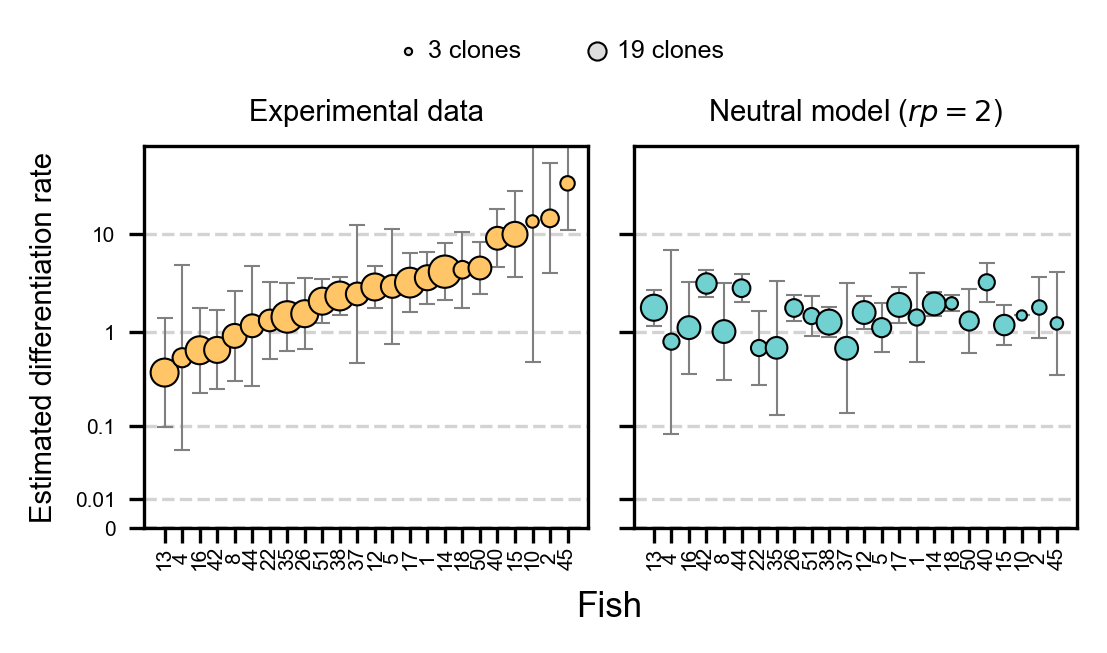

In [29]:
plt.style.use('default')
plt.rcParams.update(small_label_settings)

fig, axes = plt.subplots(1, 2, figsize = (3.7, 2), dpi = 300, sharey = True)

for ax, summary, title, color in zip(
    axes,
    [exp_summary_sorted, sim_summary_sorted],
    ['Experimental data', 'Neutral model ($rp=2$)'],
    [exp_hue, hue(4)]
):
    xpos = range(len(summary))

    ax.errorbar(
        xpos, summary['mean'],
        yerr = [summary['mean'] - summary['ci_low'], summary['ci_high'] - summary['mean']],
        fmt = 'none', ecolor = 'gray', capsize = 2, lw = 0.5, capthick = 0.5
    )

    sizes = 3 * summary['count']
    ax.scatter(
        xpos, summary['mean'],
        s = sizes, facecolor = color, edgecolor = 'black', zorder = 3, lw = 0.5
    )

    ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax.set_title(title)
    ax.set_xticks(xpos)
    ax.set_xticklabels(summary['fish'], size=5, rotation=90, va='center')
    ax.grid(True, linestyle='--', linewidth=0.8, color='lightgray', axis='y')

# Shared y-axis formatting
tick_r = [0, 1e-2, 1e-1, 1, 10, 100]
tick_symlog = symlog10(np.array(tick_r), linthresh=1e-2)
axes[0].set_ylabel('Estimated differentiation rate')
for ax in axes:
    ax.set_yticks(tick_symlog)
    ax.set_yticklabels([str(r) for r in tick_r])
    ax.set_ylim([0, 3.9])

fig.supxlabel('Fish', x=0.55, y = 0.07)

# Custom legend handles
sizes = [3, 19]
legend_handles = [
    plt.scatter([], [], s=size, color='#dddddd',
                edgecolors='black', linewidths=0.5)
    for size in sizes
]

leg = fig.legend(
    legend_handles,
    [f'{size} clones' for size in sizes],
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=3, 
    fontsize=6,
    handletextpad=-0.2
)

plt.tight_layout()
filepath = os.path.join('images', 'anova.svg')
plt.savefig(filepath, bbox_inches = 'tight', pad_inches = 0)

In [35]:
dep_var = 'symlog10_r'

In [36]:
def residuals(group):
    return group[dep_var] - group[dep_var].mean()

def between_within_variance(df, exp_scenario, sim_scenario, duplicate):
    df2 = df.query('scenario == @exp_scenario or (scenario == @sim_scenario and duplicate == @duplicate)')

    # Fish-level means
    fish_means = df2.groupby(['scenario','fish'])[dep_var].mean().reset_index()
    
    exp_means = fish_means.loc[fish_means['scenario'] == exp_scenario, dep_var]
    sim_means = fish_means.loc[fish_means['scenario'] == sim_scenario, dep_var]
    
    # Between-fish variance test
    between_test = levene(exp_means, sim_means)
    
    resids = df2.groupby(['scenario','fish']).apply(residuals, include_groups = False).reset_index(level = [0,1])
    
    exp_resids = resids.loc[resids['scenario'] == exp_scenario, dep_var]
    sim_resids = resids.loc[resids['scenario'] == sim_scenario, dep_var]
    
    # Within-fish variance test
    within_test = levene(exp_resids, sim_resids)

    return between_test, within_test

between_test, within_test = between_within_variance(df, exp_scenario, sim_scenario, 0)
print(f"Between-fish variance test: {between_test.statistic:.2f} (p = {between_test.pvalue:.3e}).")
print(f"Within-fish variance test: {within_test.statistic:.2f} (p = {within_test.pvalue:.3e}).")

Between-fish variance test: 12.81 (p = 8.265e-04).
Within-fish variance test: 22.21 (p = 3.262e-06).


In [37]:
exp_scenario = 'full_pipeline'

rows = []
for d in df['duplicate'].unique():
    # print(f'Duplicate {d}:')
    between_test, within_test = between_within_variance(df, exp_scenario, sim_scenario, d)
    row = {'duplicate': d, 'between p': between_test.pvalue, 'within p': within_test.pvalue}
    rows.append(row)
    # print(f" - Between-fish variance test: {between_test.statistic:.2f} (p = {between_test.pvalue:.3e}).")
    # print(f" - Within-fish variance test: {within_test.statistic:.2f} (p = {within_test.pvalue:.3e}).")

results_df = pd.DataFrame(rows)
results_df

,duplicate,between p,within p
0,0,0.000826,3.261541e-06
1,1,0.012149,2.331318e-07
2,2,0.001571,3.174855e-08
3,3,0.002914,1.302729e-07
4,4,0.026403,1.245163e-07
5,5,0.170668,1.299985e-06
6,6,0.015570,1.693026e-07
7,7,0.020727,1.686498e-04
8,8,0.004196,5.114523e-07
9,9,0.125457,2.733216e-07
